# Lecture 11: K-Means Clustering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jinming99/learn-ml-by-building/blob/main/Lecture%2011%20K-Means/11-KMeans.ipynb)

Suppose we have a pile of documents and no labels. Which ones belong together?
K-means gives us a precise answer to a narrower question: which groups keep
points close to their group means? Whether those groups are useful is still ours to judge.

We'll follow three ideas: how assignment and averaging reduce an objective,
why the starting point matters, and how to tell what a cluster actually represents.

## 1. Which Points Belong Together?

Here are 300 points, with no group labels shown. How many groups would you choose?
What would make one grouping more convincing than another?

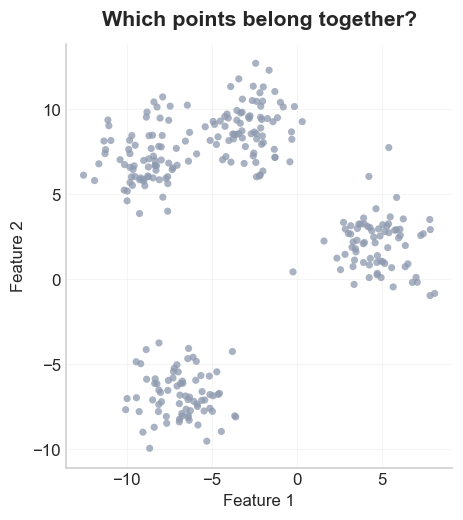

In [1]:
import base64
from html import escape
from io import BytesIO
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from IPython.display import HTML, display
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.datasets import fetch_20newsgroups, make_blobs, make_moons, make_circles
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from threadpoolctl import threadpool_limits

COLORS = np.array(['#3A86FF', '#E76F51', '#2A9D8F', '#9467BD', '#D49A22', '#657786'])
INK, MUTED = '#263238', '#8D99AE'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 14,
                     'axes.titleweight': 'bold', 'axes.titlepad': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'grid.alpha': .18, 'legend.frameon': False,
                     'animation.embed_limit': 30})


def plot_groups(ax, points, labels=None, centers=None):
    ax.scatter(*points.T, c=MUTED if labels is None else COLORS[labels],
               s=22, alpha=.75, edgecolors='none')
    if centers is not None:
        ax.scatter(*centers.T, c=COLORS[:len(centers)], marker='X', s=160,
                   edgecolors=INK, linewidths=1.3, zorder=5)
    ax.set(xlabel='Feature 1', ylabel='Feature 2', aspect='equal')


def png_data(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', bbox_inches='tight', dpi=120)
    return base64.b64encode(buffer.getvalue()).decode('ascii')


X_simple, toy_source_labels = make_blobs(n_samples=300, centers=4, cluster_std=1.5,
                                       center_box=(-10, 10), random_state=42)
toy_limits = (X_simple.min(axis=0) - 1.5, X_simple.max(axis=0) + 1.5)
fig, ax = plt.subplots(figsize=(8, 5))
plot_groups(ax, X_simple)
ax.set_title('Which points belong together?')
plt.show()

## 2. Assign. Average. Repeat.

Let's choose $k=4$ for now. K-means minimizes **inertia**, the total squared
distance from each point to its assigned center:

$$J(c,\mu)=\sum_{i=1}^{n}\|x_i-\mu_{c_i}\|^2.$$

With the centers fixed, assign each point to the nearest one:
$c_i\leftarrow\arg\min_j\|x_i-\mu_j\|^2$.
With the assignments fixed, move each center to its group's mean:
$\mu_j\leftarrow\frac{1}{|S_j|}\sum_{i\in S_j}x_i$.
Neither step increases $J$. Notice what changes in each step—and what stays fixed.

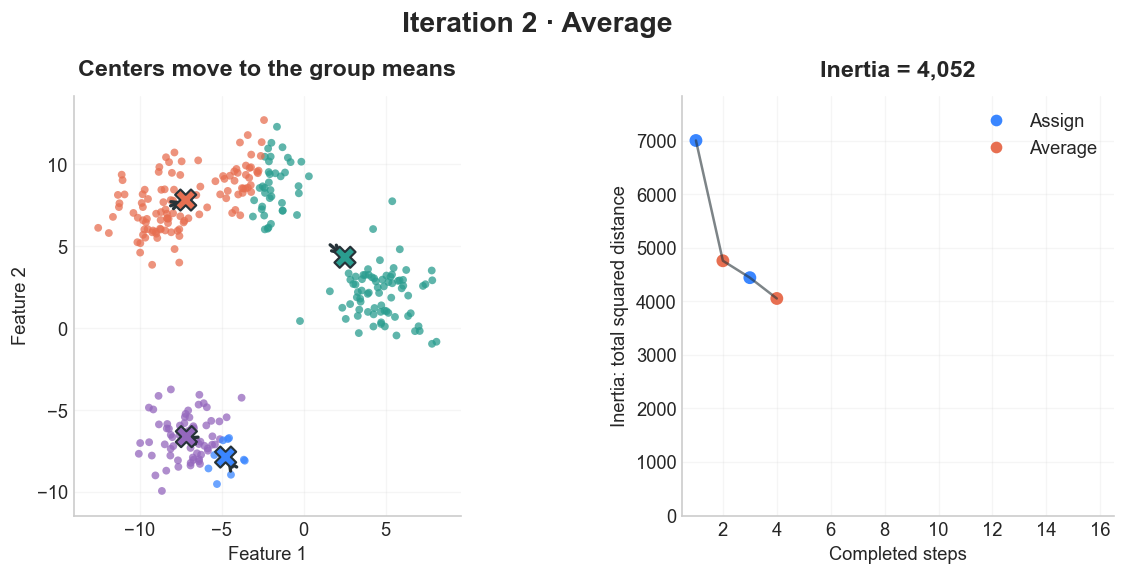

In [2]:
def lloyd_steps(points, k, seed=3, max_iter=30, tol=1e-8):
    centers = points[np.random.default_rng(seed).choice(len(points), k, replace=False)].copy()
    history = []
    for iteration in range(1, max_iter + 1):
        labels = ((points[:, None] - centers) ** 2).sum(axis=2).argmin(axis=1)
        history.append(dict(phase='Assign', iteration=iteration, centers=centers.copy(),
                            labels=labels.copy(), previous=centers.copy(),
                            inertia=((points - centers[labels]) ** 2).sum()))
        updated = np.array([points[labels == j].mean(axis=0) if np.any(labels == j)
                            else centers[j] for j in range(k)])
        history.append(dict(phase='Average', iteration=iteration, centers=updated.copy(),
                            labels=labels.copy(), previous=centers.copy(),
                            inertia=((points - updated[labels]) ** 2).sum()))
        movement = np.linalg.norm(updated - centers)
        centers = updated  # Keep the update even when it satisfies the stopping rule.
        if movement <= tol:
            break
    # Labels must correspond to the returned centers, even at an iteration limit.
    labels = ((points[:, None] - centers) ** 2).sum(axis=2).argmin(axis=1)
    return labels, centers, history


toy_labels, toy_centers, history = lloyd_steps(X_simple, 4)
animation_fig, (scene, objective) = plt.subplots(1, 2, figsize=(12, 5),
                                              gridspec_kw={'width_ratios': [1.25, 1]})
animation_fig.subplots_adjust(wspace=.3, top=.84, bottom=.14)
costs = np.array([step['inertia'] for step in history])


def draw_step(frame):
    step = history[frame]
    scene.clear()
    objective.clear()
    plot_groups(scene, X_simple, step['labels'], step['centers'])
    scene.set(xlim=(toy_limits[0][0], toy_limits[1][0]),
              ylim=(toy_limits[0][1], toy_limits[1][1]))
    scene.set_title('Nearest-center assignments' if step['phase'] == 'Assign'
                    else 'Centers move to the group means')
    if step['phase'] == 'Average':
        for old, new in zip(step['previous'], step['centers']):
            scene.annotate('', xy=new, xytext=old,
                           arrowprops=dict(arrowstyle='->', color=INK, lw=2))
    x_steps = np.arange(1, frame + 2)
    objective.plot(x_steps, costs[:frame + 1], color=INK, lw=1.5, alpha=.6)
    objective.scatter(x_steps, costs[:frame + 1], s=45,
                      c=[COLORS[0] if i % 2 == 1 else COLORS[1] for i in x_steps])
    objective.set(xlim=(.5, len(history) + .5), ylim=(0, costs.max() * 1.12),
                  xlabel='Completed steps', ylabel='Inertia: total squared distance',
                  title=f"Inertia = {step['inertia']:,.0f}")
    objective.xaxis.set_major_locator(MaxNLocator(integer=True))
    objective.legend(handles=[Line2D([], [], marker='o', ls='', color=COLORS[0], label='Assign'),
                              Line2D([], [], marker='o', ls='', color=COLORS[1], label='Average')],
                     loc='upper right')
    animation_fig.suptitle(f"Iteration {step['iteration']} · {step['phase']}", fontsize=17, weight='bold')


animation = FuncAnimation(animation_fig, draw_step, frames=len(history), interval=950, repeat=False)
animation_html = animation.to_jshtml(default_mode='once')
draw_step(min(3, len(history) - 1))
preview = png_data(animation_fig)
plt.close(animation_fig)
# HTML plays in a trusted notebook; the PNG is the saved noninteractive fallback.
display({'text/html': animation_html, 'image/png': preview,
         'text/plain': 'K-means: alternating assignments and mean updates.'}, raw=True)

## 3. Does the Starting Point Matter?

The objective falls, but that doesn't mean we've found its best possible value.
We'll keep the points and $k$ fixed and change only the starting centers.
**K-means++** spreads its initial centers using squared-distance-weighted sampling;
it improves the odds of a good start, but does not guarantee the best solution.

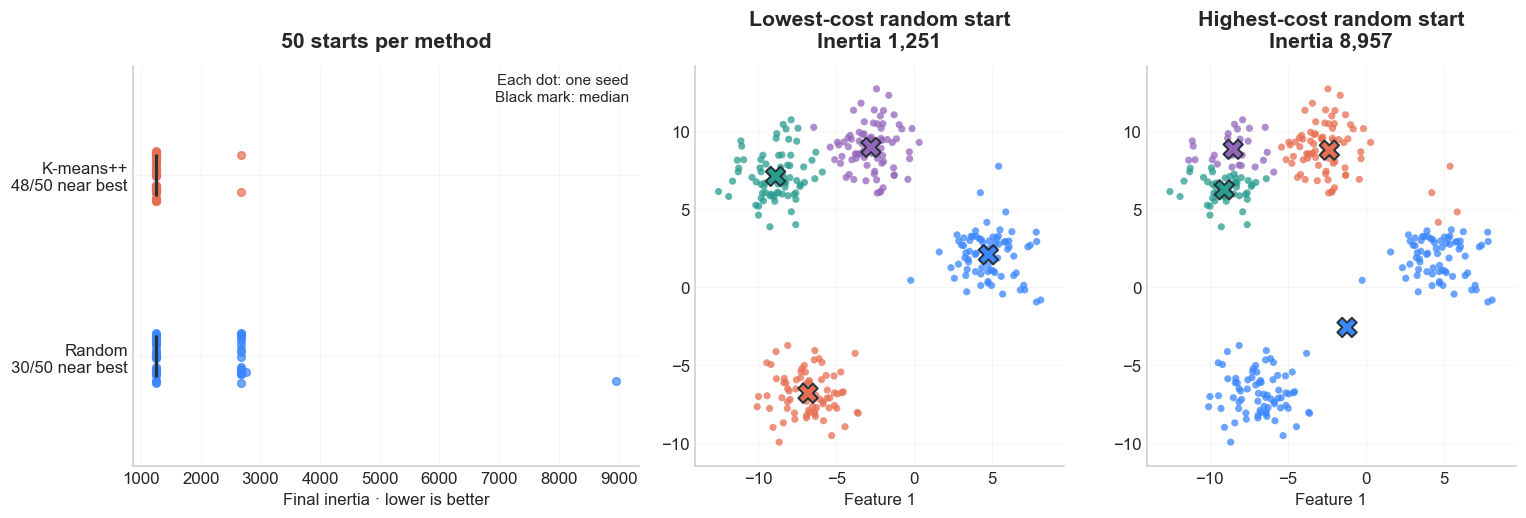

In [3]:
initialization_runs = {}
with threadpool_limits(limits=1):
    for method in ['random', 'k-means++']:
        initialization_runs[method] = [KMeans(n_clusters=4, init=method, n_init=1,
                                             random_state=seed).fit(X_simple)
                                       for seed in range(50)]

fig = plt.figure(figsize=(14, 4.6), layout='constrained')
axes = fig.subplots(1, 3, gridspec_kw={'width_ratios': [1.2, 1, 1]})
best_observed = min(model.inertia_ for models in initialization_runs.values() for model in models)
near_best = {}
for row, (method, models) in enumerate(initialization_runs.items()):
    inertia = np.array([model.inertia_ for model in models])
    near_best[method] = int((inertia <= 1.01 * best_observed).sum())
    jitter = np.random.default_rng(123).uniform(-.15, .15, len(models))
    axes[0].scatter(inertia, row + jitter, color=COLORS[row], s=25, alpha=.7)
    axes[0].plot(np.median(inertia), row, marker='|', ms=28, mew=2, color=INK)
axes[0].set(yticks=[0, 1], yticklabels=[f'Random\n{near_best["random"]}/50 near best',
                                      f'K-means++\n{near_best["k-means++"]}/50 near best'],
            xlabel='Final inertia · lower is better', title='50 starts per method', ylim=(-.6, 1.6))
axes[0].text(.98, .98, 'Each dot: one seed\nBlack mark: median', transform=axes[0].transAxes,
             ha='right', va='top', fontsize=10)
random_runs = initialization_runs['random']
low = min(random_runs, key=lambda model: model.inertia_)
high = max(random_runs, key=lambda model: model.inertia_)
for ax, model, title in zip(axes[1:], [low, high], ['Lowest-cost random start', 'Highest-cost random start']):
    plot_groups(ax, X_simple, model.labels_, model.cluster_centers_)
    ax.set(xlim=(toy_limits[0][0], toy_limits[1][0]), ylim=(toy_limits[0][1], toy_limits[1][1]),
           title=f'{title}\nInertia {model.inertia_:,.0f}')
    ax.set_ylabel('')
plt.show()

Every dot is a different seed, with **one initialization** (`n_init=1`). The two
spatial examples are the lowest- and highest-inertia random runs, not typical runs.
“Near best” means within 1% of the lowest inertia observed across these 100 runs.
In later fits, `n_init=10` keeps
the lowest-inertia result from ten starts; it still cannot promise a global minimum.

## 4. What Did We Actually Group?

Let's organize real posts from [20 Newsgroups](https://scikit-learn.org/stable/datasets/real_world.html#the-20-newsgroups-text-dataset):
graphics, baseball, medicine, and Middle East politics. The topic labels stay out
of the fit. We'll use them afterward to ask whether the groups resemble topics.
We begin with $k=4$ because we selected four forums, not because that proves there
are four geometric clusters.

A document becomes a vector of **TF–IDF weights**: frequent terms within a post
count more, while terms appearing in many posts count less. Here the library uses
$\mathrm{idf}(t)=\log\frac{1+n}{1+\mathrm{df}(t)}+1$, then normalizes each document
to unit length. The vocabulary keeps up to 2,000 frequent surviving words and
two-word phrases—not necessarily the 2,000 most meaningful ones.

In [4]:
news = fetch_20newsgroups(subset='train', random_state=42,
                         categories=['comp.graphics', 'rec.sport.baseball',
                                     'sci.med', 'talk.politics.mideast'],
                         remove=('headers', 'footers', 'quotes'))
vectorizer = TfidfVectorizer(max_features=2000, stop_words='english',
                            max_df=.5, min_df=5, ngram_range=(1, 2))
X_all = vectorizer.fit_transform(news.data)
nonempty = X_all.getnnz(axis=1) > 0
X_text = X_all[nonempty]
document_ids = np.flatnonzero(nonempty)
reference_topics = news.target[nonempty]
terms = vectorizer.get_feature_names_out()
topic_names = ['Graphics', 'Baseball', 'Medicine', 'Politics']
print(f'{len(news.data):,} posts → {len(document_ids):,} usable posts; '
      f'{(~nonempty).sum()} have no surviving features and are excluded.')
print(f'{X_text.shape[1]:,} features; {1 - X_text.nnz / np.prod(X_text.shape):.1%} zeros.')
with threadpool_limits(limits=1):
    text_model = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_text)

2,339 posts → 2,251 usable posts; 88 have no surviving features and are excluded.
2,000 features; 98.0% zeros.


Each row below is one cluster. The percentages tell us where its posts came
from; the words have the largest weights in its centroid. Would you give each
row a topic name? Is any row grouping something else?

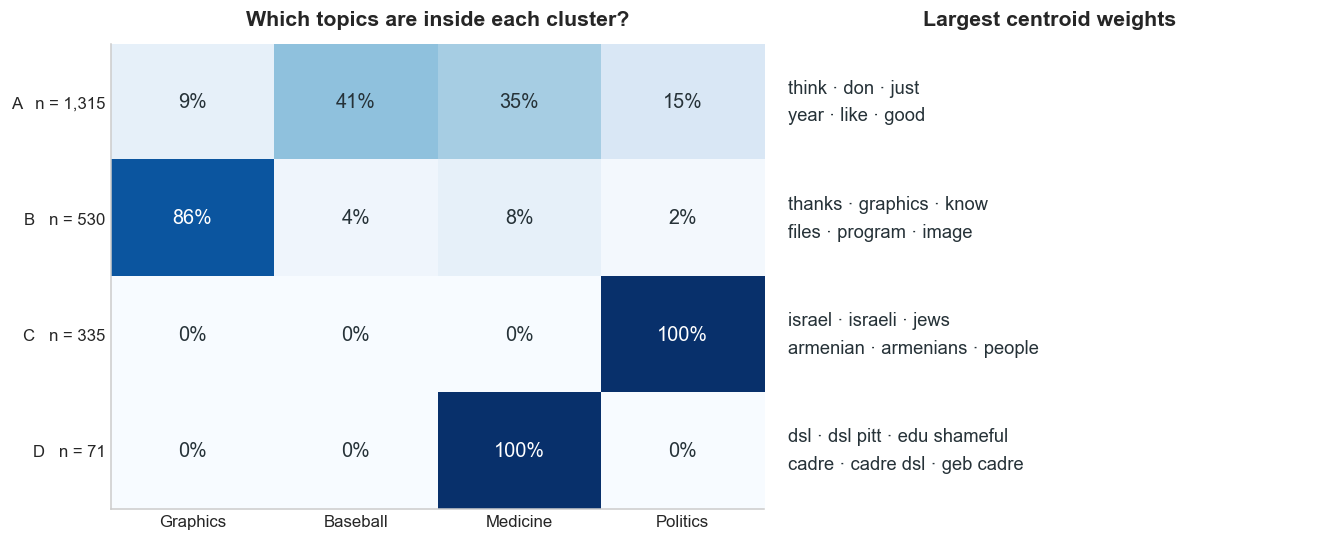

In [5]:
sizes = np.bincount(text_model.labels_, minlength=4)
cluster_order = np.argsort(-sizes)
cluster_letter = {cluster: 'ABCD'[row] for row, cluster in enumerate(cluster_order)}
composition = np.array([np.bincount(reference_topics[text_model.labels_ == cluster], minlength=4)
                        for cluster in cluster_order])
shares = composition / composition.sum(axis=1, keepdims=True)
fig, (heat, words) = plt.subplots(1, 2, figsize=(12, 4.8),
                                 gridspec_kw={'width_ratios': [1.2, 1]}, layout='constrained')
heat.imshow(shares, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for row in range(4):
    for col in range(4):
        heat.text(col, row, f'{shares[row, col]:.0%}', ha='center', va='center',
                  fontsize=13, color='white' if shares[row, col] > .55 else INK)
heat.set(xticks=range(4), xticklabels=topic_names, yticks=range(4),
         yticklabels=[f'{cluster_letter[c]}   n = {sizes[c]:,}' for c in cluster_order],
         title='Which topics are inside each cluster?')
heat.grid(False)
words.set(xlim=(0, 1), ylim=(3.5, -.5), title='Largest centroid weights')
words.axis('off')
for row, cluster in enumerate(cluster_order):
    top = terms[text_model.cluster_centers_[cluster].argsort()[-6:][::-1]]
    words.text(.02, row, ' · '.join(top[:3]) + '\n' + ' · '.join(top[3:]),
               va='center', fontsize=12, linespacing=1.7, color=INK)
plt.show()

In [6]:
# These two short excerpts were selected to inspect the shared-signature cluster.
# Document IDs refer to the fetched, shuffled subset; contact details are omitted.
cards = []
for original_id in [7, 29]:
    row = np.flatnonzero(document_ids == original_id)[0]
    text = news.data[original_id]
    opening = ' '.join(text.split()[:11]) + ' …'
    tail = 'it is shameful to surrender it too soon.'
    ending = '… ' + tail if tail in text else '[no matching closing phrase]'
    cards.append(f'<div style="flex:1;min-width:240px;border-left:3px solid #8D99AE;'
                 f'padding:8px 16px"><b>Post {original_id} · cluster '
                 f'{cluster_letter[text_model.labels_[row]]}</b><p>{escape(opening)}</p>'
                 f'<p>{escape(ending)}</p></div>')
display(HTML('<div style="display:flex;gap:20px;flex-wrap:wrap">' + ''.join(cards) + '</div>'))
signature_cluster = text_model.cluster_centers_[:, vectorizer.vocabulary_['shameful']].argmax()
signature_ids = document_ids[text_model.labels_ == signature_cluster]
shared_signature = sum('shameful' in news.data[i] and 'surrender' in news.data[i] for i in signature_ids)
display(HTML(f'<details><summary><b>What connects these posts?</b></summary><p>'
             f'{shared_signature} of the {len(signature_ids)} posts in cluster '
             f'{cluster_letter[signature_cluster]} contain this repeated closing phrase. '
             f'The body topics differ, but a signature supplies several shared features. '
             f'The loader’s footer removal is heuristic; this signature survived. '
             f'K-means found a real pattern, but not necessarily the topic structure we wanted.</p></details>'))

A low objective is evidence of compact groups in **these features**, not evidence
that we discovered the right meaning of “similar.” The reference labels provide
another check, not an absolute definition of a good clustering.

The optional projection below compresses the fitted 2,000-dimensional space into
two dimensions. It is a view of the result, not the space in which we fitted k-means.

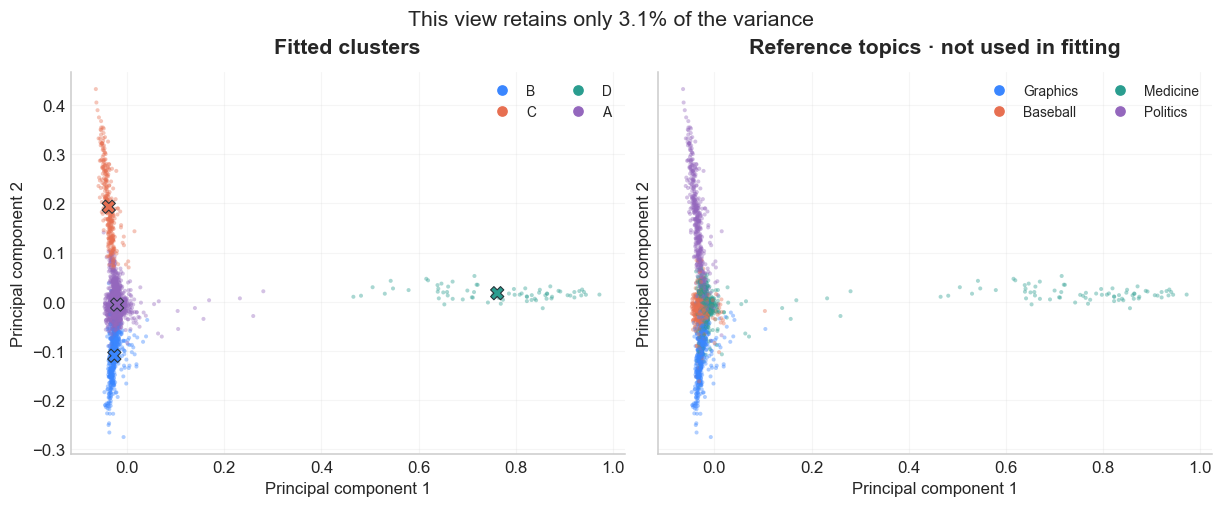

In [7]:
with threadpool_limits(limits=1):
    projection = PCA(n_components=2, svd_solver='randomized', random_state=42)
    X_2d = projection.fit_transform(X_text.toarray())
    centers_2d = projection.transform(text_model.cluster_centers_)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True, layout='constrained')
for ax, labels, title in zip(axes, [text_model.labels_, reference_topics],
                           ['Fitted clusters', 'Reference topics · not used in fitting']):
    ax.scatter(*X_2d.T, c=COLORS[labels], s=7, alpha=.4, edgecolors='none')
    ax.set(title=title, xlabel='Principal component 1', ylabel='Principal component 2')
axes[0].scatter(*centers_2d.T, c=COLORS[:4], marker='X', s=75, edgecolors=INK, linewidths=.7)
for ax, names in zip(axes, [[cluster_letter[c] for c in range(4)], topic_names]):
    ax.legend(handles=[Line2D([], [], marker='o', ls='', color=COLORS[c], label=name)
                       for c, name in enumerate(names)], fontsize=9, ncol=2, loc='upper right')
variance_kept = projection.explained_variance_ratio_.sum()
fig.suptitle(f'This view retains only {variance_kept:.1%} of the variance', fontsize=14)
plt.show()

## 5. How Many Groups Are Useful?

More centers give k-means more freedom. On the same points, a larger $k$ can split
an existing group and reduce inertia without revealing a new kind of object.
The best achievable inertia cannot increase with $k$; a particular run can still
get stuck at a poorer solution.

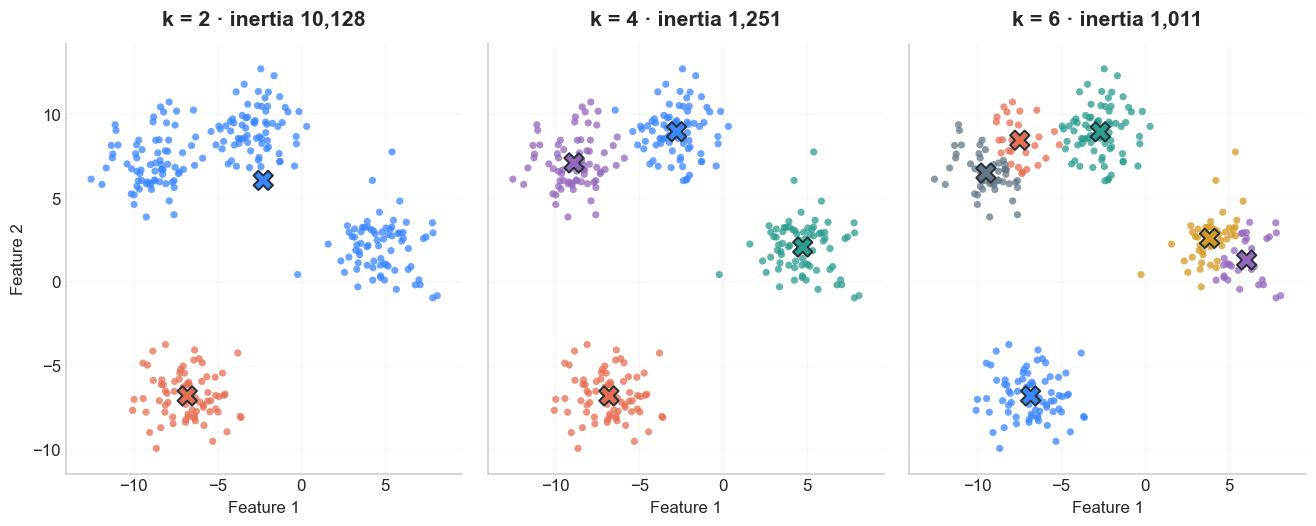

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharex=True, sharey=True, layout='constrained')
with threadpool_limits(limits=1):
    for ax, k in zip(axes, [2, 4, 6]):
        model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_simple)
        plot_groups(ax, X_simple, model.labels_, model.cluster_centers_)
        ax.set(title=f'k = {k} · inertia {model.inertia_:,.0f}',
               xlim=(toy_limits[0][0], toy_limits[1][0]), ylim=(toy_limits[0][1], toy_limits[1][1]))
        if ax is not axes[0]:
            ax.set_ylabel('')
plt.show()

Now return to the posts. Inertia measures compactness. **Silhouette** compares
a point's average distance within its own cluster ($a$) with its average distance
to the nearest other cluster ($b$): $s=(b-a)/\max(a,b)$. Larger is better; values
near zero mean little separation by this distance measure.

We'll use the same 1,000 sampled posts for every silhouette calculation and five
seeds at each $k$. Do these curves give us a convincing reason to prefer one $k$?

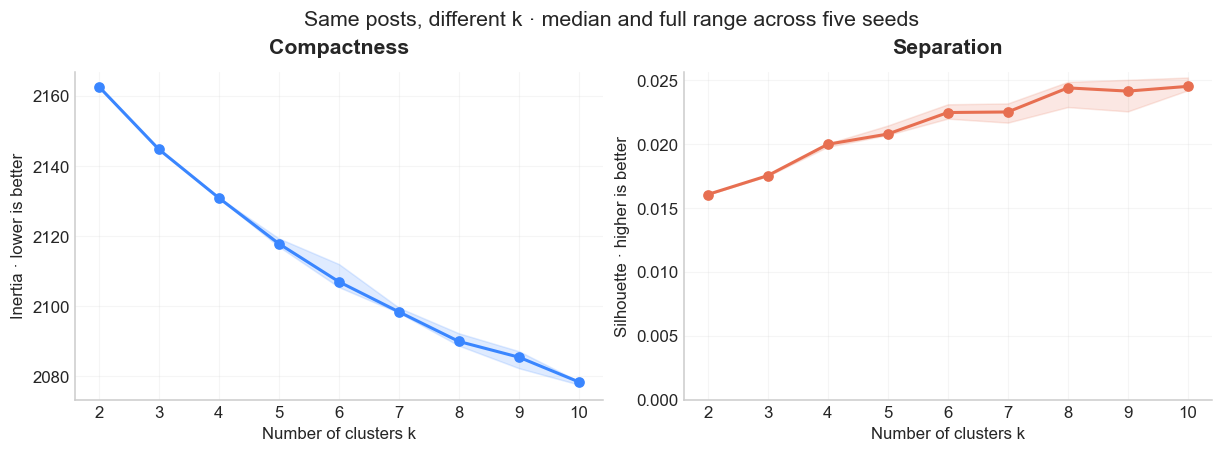

In [9]:
k_values = np.arange(2, 11)
silhouette_rows = np.random.default_rng(42).choice(len(document_ids), 1000, replace=False)
k_inertia = np.empty((len(k_values), 5))
k_silhouette = np.empty_like(k_inertia)
with threadpool_limits(limits=1):
    for row, k in enumerate(k_values):
        for seed in range(5):
            model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X_text)
            k_inertia[row, seed] = model.inertia_
            k_silhouette[row, seed] = silhouette_score(
                X_text[silhouette_rows], model.labels_[silhouette_rows])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, values, title, ylabel, color in zip(
        axes, [k_inertia, k_silhouette], ['Compactness', 'Separation'],
        ['Inertia · lower is better', 'Silhouette · higher is better'], COLORS[:2]):
    ax.fill_between(k_values, values.min(axis=1), values.max(axis=1), color=color, alpha=.16)
    ax.plot(k_values, np.median(values, axis=1), 'o-', color=color, lw=2)
    ax.set(xlabel='Number of clusters k', ylabel=ylabel, title=title, xticks=k_values)
axes[1].set_ylim(bottom=0)
fig.suptitle('Same posts, different k · median and full range across five seeds', fontsize=14)
plt.show()

There is no clean verdict here. Inertia keeps rewarding extra centers, while
silhouette remains low and depends on the solution reached. Four forum labels
do not force four compact groups in TF–IDF space. A useful choice of $k$ also needs
inspection of the groups and a purpose for using them.

## 6. When a Mean Is the Wrong Shape

K-means assigns a point to its nearest center. That makes straight decision
boundaries and convex Voronoi regions—even when the data follow a curved shape.
The pale backgrounds below show those regions; crosses mark the centers.

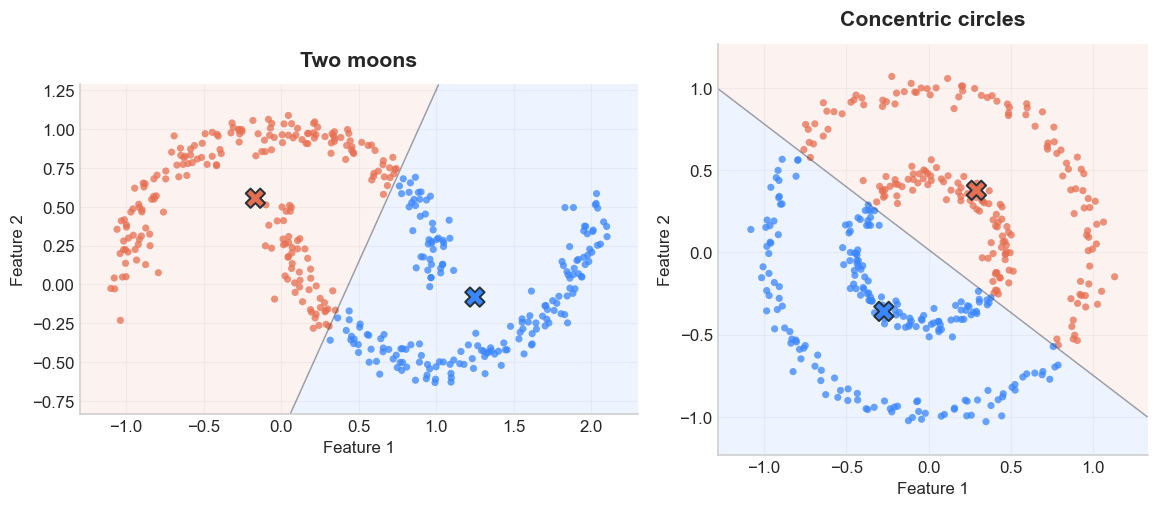

In [10]:
shape_examples = [('Two moons', make_moons(n_samples=400, noise=.065, random_state=42)),
                  ('Concentric circles', make_circles(n_samples=400, factor=.45,
                                                     noise=.045, random_state=42))]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
with threadpool_limits(limits=1):
    for ax, (title, (points, generating_labels)) in zip(axes, shape_examples):
        model = KMeans(n_clusters=2, n_init=10, random_state=42).fit(points)
        low, high = points.min(axis=0) - .2, points.max(axis=0) + .2
        xx, yy = np.meshgrid(np.linspace(low[0], high[0], 160), np.linspace(low[1], high[1], 160))
        distances = model.transform(np.c_[xx.ravel(), yy.ravel()]) ** 2
        margin = (distances[:, 0] - distances[:, 1]).reshape(xx.shape)
        ax.contourf(xx, yy, margin, levels=[margin.min() - 1, 0, margin.max() + 1],
                    cmap=ListedColormap(COLORS[:2]), alpha=.09)
        ax.contour(xx, yy, margin, levels=[0], colors=INK, linewidths=1, alpha=.4)
        plot_groups(ax, points, model.labels_, model.cluster_centers_)
        ax.set(title=title, xlim=(low[0], high[0]), ylim=(low[1], high[1]))
plt.show()

These are failures of the model's geometry, not problems that more iterations
can solve. Density-based or graph-based clustering can express different kinds
of groups. Changing feature scales also changes distances and therefore the
question k-means answers.

### Optional: Faster Updates, Same Quality?

Mini-batch k-means updates centers using small batches instead of the full dataset.
We'll compare five seeds on the same posts, with a batch size of 100. Timing alone
isn't enough: we'll also check whether the faster fit preserves topic agreement.

**Adjusted Rand index (ARI)** compares partitions without caring about cluster
numbers: 1 means identical partitions, about 0 is chance-level agreement. It can
be negative. Topic agreement is only one diagnostic, not the training objective.

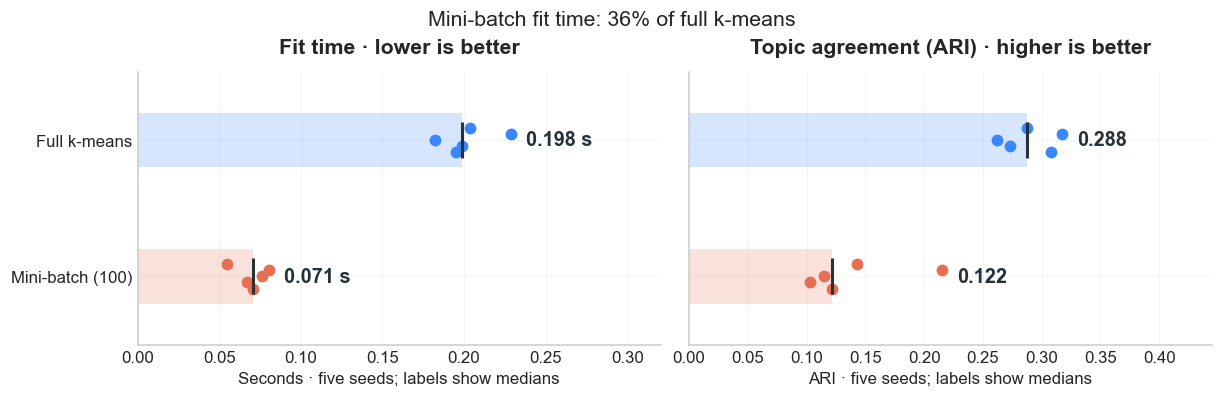

Median inertia: 2,130.8 (full) vs 2,149.9 (mini-batch). Timing is local, single-threaded, and excludes feature extraction.


In [11]:
benchmarks = {name: [] for name in ['Full k-means', 'Mini-batch (100)']}
with threadpool_limits(limits=1):
    # Warm up both paths before timing; fit time excludes feature extraction.
    for estimator in [KMeans(n_clusters=4, n_init=10, random_state=99),
                      MiniBatchKMeans(n_clusters=4, batch_size=100, n_init=10, random_state=99)]:
        estimator.fit(X_text)
    for seed in range(5):
        for name, estimator in [('Full k-means', KMeans(n_clusters=4, n_init=10, random_state=seed)),
                                ('Mini-batch (100)', MiniBatchKMeans(n_clusters=4, batch_size=100,
                                                                   n_init=10, random_state=seed))]:
            started = perf_counter()
            estimator.fit(X_text)
            seconds = perf_counter() - started
            benchmarks[name].append([seconds, estimator.inertia_,
                                     adjusted_rand_score(reference_topics, estimator.labels_)])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout='constrained')
benchmark_values = np.array(list(benchmarks.values()))
medians = np.median(benchmark_values, axis=1)
for row, (name, records) in enumerate(benchmarks.items()):
    results = np.array(records)
    for ax, col in zip(axes, [0, 2]):
        ax.barh(row, medians[row, col], height=.4, color=COLORS[row], alpha=.2)
        ax.scatter(results[:, col], row + np.linspace(-.09, .09, 5), s=45, color=COLORS[row])
        ax.plot(medians[row, col], row, '|', color=INK, ms=24, mew=2)
        ax.text(results[:, col].max() + .04 * benchmark_values[:, :, col].max(), row,
                f'{medians[row, col]:.3f}' + (' s' if col == 0 else ''),
                va='center', fontsize=13, weight='bold', color=INK)
        ax.set_xlim(0, benchmark_values[:, :, col].max() * 1.4)
for ax, title in zip(axes, ['Fit time · lower is better', 'Topic agreement (ARI) · higher is better']):
    ax.set(yticks=[0, 1], yticklabels=list(benchmarks) if ax is axes[0] else [],
           ylim=(1.5, -.5), title=title)
axes[0].set_xlabel('Seconds · five seeds; labels show medians')
axes[1].set_xlabel('ARI · five seeds; labels show medians')
fig.suptitle(f'Mini-batch fit time: {medians[1, 0] / medians[0, 0]:.0%} of full k-means', fontsize=14)
plt.show()
print(f'Median inertia: {medians[0, 1]:,.1f} (full) vs {medians[1, 1]:,.1f} (mini-batch). '
      'Timing is local, single-threaded, and excludes feature extraction.')

The smaller batches fit faster here, but match the forum topics less well—even
though the inertia values are close. Faster optimization is not automatically
an equally useful grouping. This is one dataset and one batch size, not a general
verdict against mini-batch k-means.

## Wrap-Up

K-means alternates between nearest-center assignments and group means, reducing
squared distance until it settles. Its answer depends on the representation,
the number of centers, and the starting point. Multiple starts help with optimization,
but they cannot decide what makes a group useful: our text example even found a
shared signature. Inspect the members, compare more than one diagnostic, and ask
whether distance to a mean captures the structure you care about.

Sources: [20 Newsgroups](http://qwone.com/~jason/20Newsgroups/),
[TF–IDF implementation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html),
[mini-batch implementation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html).